# Init:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [2]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

ModuleNotFoundError: No module named 'ijson'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [ ]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Using GPU for spaCy.
Processing TriviaQA:


Classifying Answers: 100%|███████████████████████████████████████████████████████| 78260/78260 [19:38<00:00, 66.39it/s]


Processing Natural Questions:


Extracting Entities:  24%|████████████▋                                         | 25153/106926 [09:02<28:32, 47.75it/s]

In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 225869 Q-A pairs out of original 272007(83%).


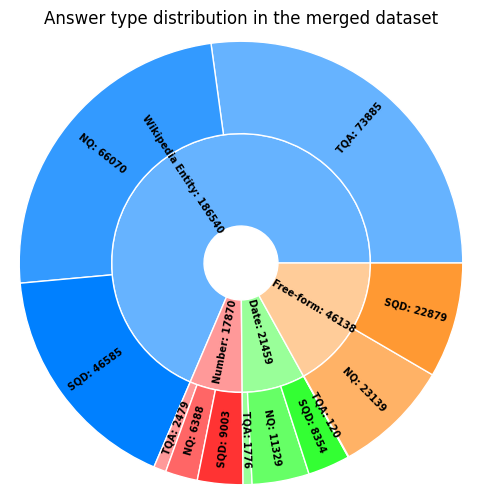

In [38]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [49]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: How many million years ago did the evolution of chimpanzees and humans diverge?
Answer: five
Type: Number
Normalized: five
Question: "What director created the popular 1980's films ""The Breakfast Club"", ""Sixteen Candles"", and ""Ferris Bueller's Day Off""?"
Answer: John Hughes
Type: Wikipedia Entity
Normalized: John Hughes
Question: where did the last name webb originate from
Answer: Northern Ireland
Type: Wikipedia Entity
Normalized: Northern Ireland
Question: May 25, 1787 saw the sitting of the Constitutional Convention. In what city did the delegates meet?
Answer: Philadelphia
Type: Wikipedia Entity
Normalized: Philadelphia
Question: During what dynasty did Nanjing become a thriving textile city?
Answer: the Song dynasty
Type: Wikipedia Entity
Normalized: Song
Question: what is the maximum number of electrons in the first energy shell of an atom
Answer: two electrons
Type: Number
Normalized: two electrons
Question: once upon a time in mumbaai based on whose story
Answer

In [2]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

# 3. Group questions:

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.group_questions import generate_embeddings, cluster_wiki_entities

In [4]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [5]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_wiki_entities(num_data)
date_clusters = cluster_wiki_entities(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)}')
print(f'Numerical: {len(num_clusters)}')
print(f'Date & Time: {len(date_clusters)}')

Clustering Entity Questions: 100%|██████████████████████████████████████████| 21459/21459 [00:00<00:00, 1375937.41it/s]

Total candidate clusters:
Entities: 26766
Numerical: 1316
Date & Time: 1183


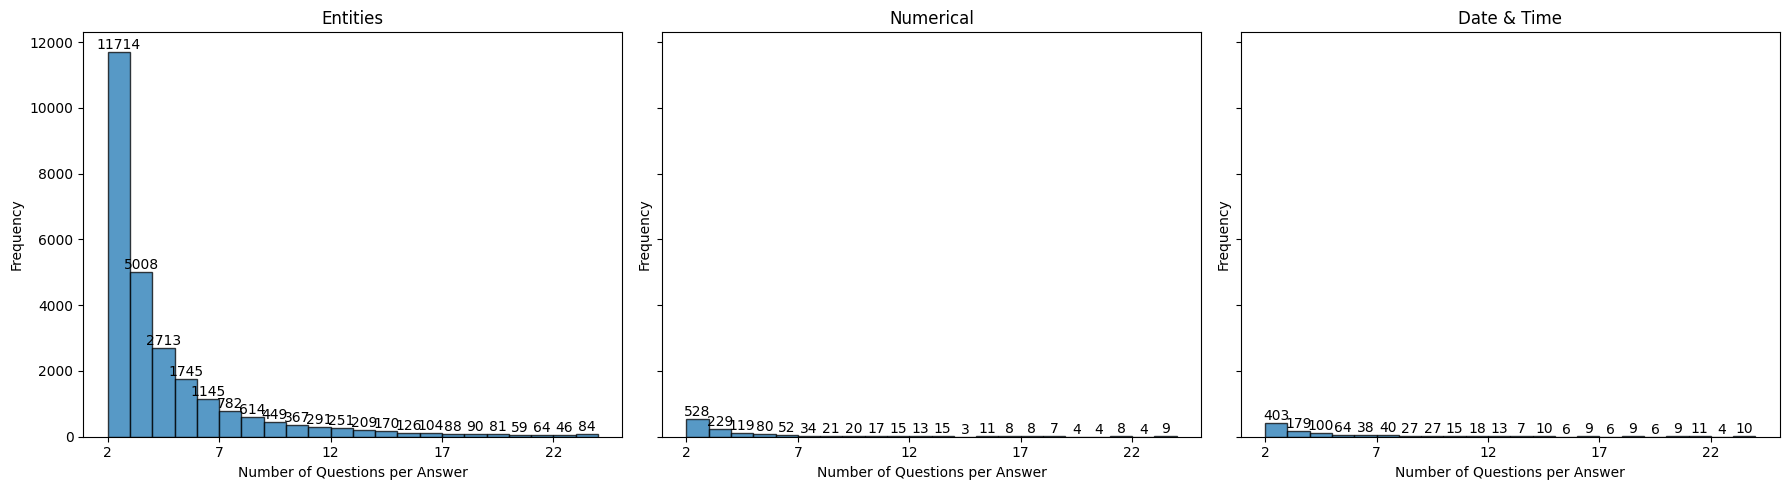

In [38]:
from knowledge_maze.create_dataset.group_questions import plot_answer_distributions
plot_answer_distributions({'Entities': ent_clusters, 'Numerical': num_clusters, 'Date & Time': date_clusters})

## 3.1 - Cluster and filter entity questions:

In [7]:
from knowledge_maze.create_dataset.group_questions import generate_question_embeddings
# Generate embeddings for all entity questions:
entity_questions_embeddings = generate_question_embeddings(ent_clusters, batch_size=256)

100%|████████████████████████████████████████████████████████████████████████████████| 542/542 [44:12<00:00,  4.89s/it]


Answer: Calgary
Questions before filtring:
1. What is the largest city in the province of Alberta, Canada?
2. At which Olympics, city or year, did Eddie the Eagle take part?
3. where is the canadian music hall of fame located
4. where was the movie hold the dark filmed
5. where is wynonna earp supposed to take place
6. where was very merry daughter of the bride filmed
7. where was bury my heart at wounded knee filmed
8. where was a very merry daughter of the bride filmed
9. where was tucker and dale vs evil filmed


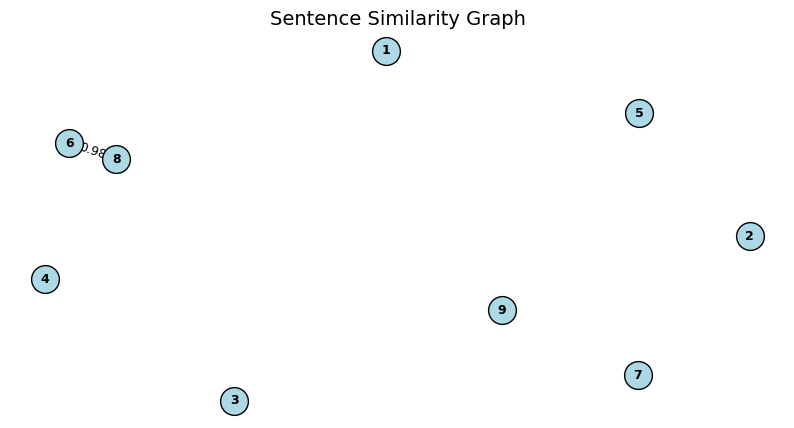

Questions after filtring:
1. What is the largest city in the province of Alberta, Canada?
2. At which Olympics, city or year, did Eddie the Eagle take part?
3. where is the canadian music hall of fame located
4. where was the movie hold the dark filmed
5. where is wynonna earp supposed to take place
6. where was bury my heart at wounded knee filmed
7. where was a very merry daughter of the bride filmed
8. where was tucker and dale vs evil filmed


In [32]:
from random import choice
from knowledge_maze.create_dataset.group_questions import generate_sentence_similarity_graph, plot_sentence_graph, remaining_nodes_after_vertex_cover

rand_sample = choice(list(ent_clusters.items()))
print('=' * 50)
print(f'Answer: {rand_sample[0]}')
print('=' * 50)
print('Questions before filtring:')
for i, sentence in enumerate(rand_sample[1]):
    print(f'{i+1}. {sentence}')
graph = generate_sentence_similarity_graph(rand_sample[1], entity_questions_embeddings, threshold=0.7)
plot_sentence_graph(graph)
print('=' * 50)
filtered_questions = remaining_nodes_after_vertex_cover(graph)
print('Questions after filtring:')
for i, sentence in enumerate(filtered_questions):
    print(f'{i+1}. {sentence}')

In [33]:
from knowledge_maze.create_dataset.group_questions import filter_question_groups

filtered_ent_clusters = filter_question_groups(ent_clusters, entity_questions_embeddings)

100%|██████████████████████████████████████████████████████████████████████████| 26766/26766 [00:20<00:00, 1321.13it/s]


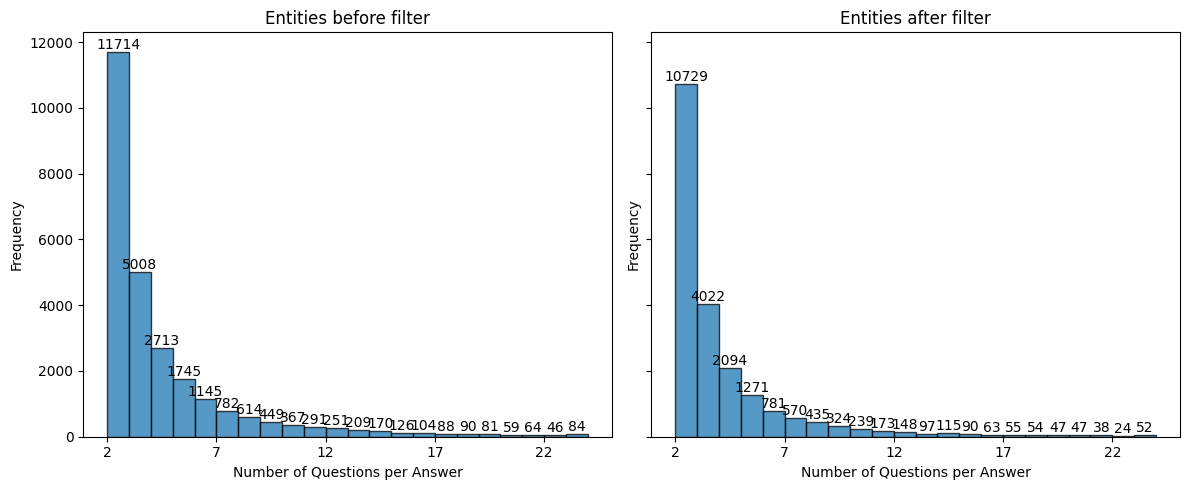

In [39]:
plot_answer_distributions({'Entities before filter': ent_clusters, 'Entities after filter': filtered_ent_clusters})

In [40]:
# Save in folder:
output_path = f"{REPO_PATH}\data_files\\filtered_cluster_ents.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(filtered_ent_clusters, out_file)

In [41]:
# Load from folder:
filtered_ent_clusters = load_json(f"{REPO_PATH}\data_files\\filtered_cluster_ents.json")

## 3.2 - Cluster and filter numerical questions: